# Credit Risk Scorecard: Predicting 30+ Days Past Due

**Goal:** predict `Bad_label` (1 = customer becomes 30+ days past due, 0 = stays current) for a bank's current credit-card customers, and compare against the bank's existing model (**Gini = 37.9**).

**Data:** three related MySQL tables: account / payment history (186,329 rows), credit enquiries (413,188 rows) and customer demographics with the target (23,896 customers, 4.2% "bad").

**Approach:** aggregate to one row per customer, select features with Weight of Evidence (WOE) / Information Value (IV), fit an interpretable Logistic Regression scorecard, and evaluate with Gini (2 x AUC - 1), 5-fold stratified cross-validation and decile rank-ordering.

> **Reproducibility note:** the data sits in a private training database, so credentials are not included. Set the environment variables listed in the README to re-run. The outputs saved below come from the original run. Feature meanings are **inferred** from value patterns because the 79 demographic features are anonymised.

In [1]:
import os
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

# Credentials are read from environment variables so no secrets live in the notebook.
# Set DB_HOST, DB_PORT, DB_USER, DB_PASSWORD and DB_NAME before running (see README.md).
HOST = os.environ["DB_HOST"]
PORT = int(os.environ.get("DB_PORT", "3306"))
USER = os.environ["DB_USER"]
PASSWORD = os.environ["DB_PASSWORD"]
DATABASE = os.environ["DB_NAME"]

# URL-encode the password so special characters (@, !, &, $) don't break the connection string
connection_string = f"mysql+pymysql://{USER}:{quote_plus(PASSWORD)}@{HOST}:{PORT}/{DATABASE}"
engine = create_engine(connection_string)

# Sanity check: list the tables in the database
print(pd.read_sql("SHOW TABLES;", engine))

  Tables_in_project_banking
0              Cust_Account
1         Cust_Demographics
2              Cust_Enquiry


In [2]:
account_df = pd.read_sql("SELECT * FROM Cust_Account;", engine)
enquiry_df = pd.read_sql("SELECT * FROM Cust_Enquiry;", engine)
demographics_df = pd.read_sql("SELECT * FROM Cust_Demographics;", engine)

print("Cust_Account shape:", account_df.shape)
print("Cust_Enquiry shape:", enquiry_df.shape)
print("Cust_Demographics shape:", demographics_df.shape)

Cust_Account shape: (186329, 21)
Cust_Enquiry shape: (413188, 6)
Cust_Demographics shape: (23896, 83)


In [3]:
# Schema only: raw rows are deliberately not displayed
for name, df in [("Cust_Account", account_df), ("Cust_Enquiry", enquiry_df), ("Cust_Demographics", demographics_df)]:
    print(f"=== {name} ===")
    df.info()
    print()

=== Cust_Account ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186329 entries, 0 to 186328
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   dt_opened            186329 non-null  object
 1   customer_no          186329 non-null  object
 2   upload_dt            186329 non-null  object
 3   acct_type            186329 non-null  object
 4   owner_indic          186329 non-null  object
 5   opened_dt            186329 non-null  object
 6   last_paymt_dt        186329 non-null  object
 7   closed_dt            186329 non-null  object
 8   reporting_dt         186329 non-null  object
 9   high_credit_amt      186329 non-null  object
 10  cur_balance_amt      186329 non-null  object
 11  amt_past_due         186329 non-null  object
 12  paymenthistory1      186329 non-null  object
 13  paymenthistory2      186329 non-null  object
 14  paymt_str_dt         186329 non-null  object
 15  paymt_end_dt 

In [4]:
# Date columns (format looks like "10-Nov-15")
account_date_cols = ['dt_opened', 'upload_dt', 'opened_dt', 'last_paymt_dt',
                      'closed_dt', 'reporting_dt', 'paymt_str_dt', 'paymt_end_dt']

for col in account_date_cols:
    account_df[col] = pd.to_datetime(account_df[col], format='%d-%b-%y', errors='coerce')

# Numeric columns - currently strings, with blanks representing missing values
account_numeric_cols = ['high_credit_amt', 'cur_balance_amt', 'amt_past_due',
                          'creditlimit', 'cashlimit', 'rateofinterest',
                          'paymentfrequency', 'actualpaymentamount']

for col in account_numeric_cols:
    account_df[col] = account_df[col].astype(str).str.strip()
    account_df[col] = account_df[col].replace('', np.nan)
    account_df[col] = pd.to_numeric(account_df[col], errors='coerce')

print("Cust_Account dtypes after conversion:")
print(account_df.dtypes)

Cust_Account dtypes after conversion:
dt_opened              datetime64[ns]
customer_no                    object
upload_dt              datetime64[ns]
acct_type                      object
owner_indic                    object
opened_dt              datetime64[ns]
last_paymt_dt          datetime64[ns]
closed_dt              datetime64[ns]
reporting_dt           datetime64[ns]
high_credit_amt               float64
cur_balance_amt                 int64
amt_past_due                  float64
paymenthistory1                object
paymenthistory2                object
paymt_str_dt           datetime64[ns]
paymt_end_dt           datetime64[ns]
creditlimit                   float64
cashlimit                     float64
rateofinterest                float64
paymentfrequency              float64
actualpaymentamount           float64
dtype: object


In [5]:
enquiry_df['dt_opened'] = pd.to_datetime(enquiry_df['dt_opened'], format='%d-%b-%y', errors='coerce')
enquiry_df['upload_dt'] = pd.to_datetime(enquiry_df['upload_dt'], format='%d-%b-%y', errors='coerce')
enquiry_df['enquiry_dt'] = pd.to_datetime(enquiry_df['enquiry_dt'], format='%d-%b-%y', errors='coerce')

enquiry_df['enq_amt'] = pd.to_numeric(enquiry_df['enq_amt'], errors='coerce')
enquiry_df['enq_purpose'] = enquiry_df['enq_purpose'].astype(str).str.strip()

print("Cust_Enquiry dtypes after conversion:")
print(enquiry_df.dtypes)

Cust_Enquiry dtypes after conversion:
dt_opened      datetime64[ns]
customer_no            object
upload_dt      datetime64[ns]
enquiry_dt     datetime64[ns]
enq_purpose            object
enq_amt               float64
dtype: object


In [6]:
demographics_df['Bad_label'] = pd.to_numeric(demographics_df['Bad_label'], errors='coerce')

print("Bad_label distribution:")
print(demographics_df['Bad_label'].value_counts())
print("\nBad rate (% of customers who are 'bad'):")
print(f"{demographics_df['Bad_label'].mean() * 100:.2f}%")

Bad_label distribution:
Bad_label
0    22892
1     1004
Name: count, dtype: int64

Bad rate (% of customers who are 'bad'):
4.20%


In [7]:
feature_cols = [f'feature_{i}' for i in range(1, 80)]

# Cardinality of each anonymised feature (raw values are not displayed)
feature_summary_df = pd.DataFrame({
    'Feature': feature_cols,
    'Unique_Values': [demographics_df[c].nunique() for c in feature_cols],
})
print(feature_summary_df.to_string(index=False))

   Feature  Unique_Values
 feature_1              8
 feature_2            282
 feature_3            263
 feature_4              4
 feature_5              2
 feature_6              2
 feature_7            485
 feature_8             20
 feature_9             20
feature_10              8
feature_11              3
feature_12             17
feature_13             15
feature_14              3
feature_15            365
feature_16            523
feature_17            303
feature_18             13
feature_19              3
feature_20          10610
feature_21           8463
feature_22           3251
feature_23              3
feature_24            722
feature_25              3
feature_26             12
feature_27             11
feature_28             63
feature_29            965
feature_30             53
feature_31             14
feature_32              6
feature_33              3
feature_34              4
feature_35           4334
feature_36             10
feature_37             12
feature_38  

In [8]:
# Replace blank/whitespace-only strings with actual NaN across all demographic features
# (many "categories" we saw, like feature_5's blank option, are really missing values)
feature_cols = [f'feature_{i}' for i in range(1, 80)]

for col in feature_cols:
    demographics_df[col] = demographics_df[col].astype(str).str.strip()
    demographics_df[col] = demographics_df[col].replace(['', 'nan', 'None'], np.nan)

print("Missing value count per feature (top 15 worst):")
print(demographics_df[feature_cols].isnull().sum().sort_values(ascending=False).head(15))

Missing value count per feature (top 15 worst):
feature_61    23887
feature_74    23879
feature_18    23878
feature_10    23845
feature_49    23792
feature_17    22869
feature_9     22635
feature_8     22635
feature_57    21503
feature_73    20951
feature_48    18399
feature_45    13713
feature_13    13004
feature_53    11610
feature_51    11422
dtype: int64


In [9]:
demographics_df['DOB'] = pd.to_datetime(demographics_df['feature_21'], format='%d-%b-%y', errors='coerce')

# Fix century issue: pandas 2-digit year parsing can misread "65" as 2065 instead of 1965
demographics_df['DOB'] = demographics_df['DOB'].apply(
    lambda d: d.replace(year=d.year - 100) if pd.notnull(d) and d.year > 2015 else d
)

# Age as of a fixed reference point (dataset appears to be from ~2015)
reference_date = pd.Timestamp('2015-12-31')
demographics_df['Age'] = (reference_date - demographics_df['DOB']).dt.days / 365.25

print("Age summary:")
print(demographics_df['Age'].describe())

Age summary:
count    23881.000000
mean        34.354012
std          7.349123
min         18.809035
25%         29.196441
50%         32.621492
75%         37.752225
max         76.481862
Name: Age, dtype: float64


In [10]:
# feature_20, 22, 47 and 77 are near-unique (thousands of distinct values), so they behave like identifiers.
# feature_10 and feature_49 are low-cardinality codes (not identifiers); the missing-value filter below handles them.
id_like_cols = ['feature_20', 'feature_22', 'feature_47', 'feature_77']

print("Confirming these are near-unique before dropping:")
for col in id_like_cols:
    print(f"{col}: {demographics_df[col].nunique()} unique values out of {len(demographics_df)} rows")

demographics_df_clean = demographics_df.drop(columns=id_like_cols + ['feature_21'])  # feature_21 replaced by Age
print("\nShape after dropping identifier columns:", demographics_df_clean.shape)

Confirming these are near-unique before dropping:
feature_20: 10610 unique values out of 23896 rows
feature_22: 3251 unique values out of 23896 rows
feature_47: 11250 unique values out of 23896 rows
feature_77: 3124 unique values out of 23896 rows

Shape after dropping identifier columns: (23896, 80)


In [11]:
# Features with 95%+ missing values - too sparse to build any reliable signal from,
# regardless of what they represent. Moderately sparse features (77-95% missing) are KEPT
# for now - WOE/IV analysis later will judge their actual predictive value with evidence,
# since missingness itself can be informative in credit risk (e.g. undisclosed employer info).
extremely_sparse_cols = ['feature_61', 'feature_74', 'feature_18', 'feature_10', 'feature_49', 'feature_17']

demographics_df_clean = demographics_df_clean.drop(columns=extremely_sparse_cols)
print("Dropped extremely sparse (95%+ missing) features.")
print("Shape after dropping:", demographics_df_clean.shape)

Dropped extremely sparse (95%+ missing) features.
Shape after dropping: (23896, 74)


## Section 3: Aggregating Account & Enquiry Data to Customer Level

Cust_Account (186,329 rows) and Cust_Enquiry (413,188 rows) each have MULTIPLE rows per 
customer_no. Bad_label exists only ONCE per customer, in Cust_Demographics. To combine these, 
we must first collapse each customer's many accounts/enquiries into a single summary row per 
customer — e.g. "how many accounts does this customer have," "what's their average past-due 
amount" — THEN join that to demographics. Joining before aggregating would create duplicate 
Bad_label rows and break the whole modeling setup.

In [12]:
# Step 1: Compute utilisation per INDIVIDUAL account, only where creditlimit is valid (not null, > 0)
# This avoids mixing account types that don't report a credit limit (e.g. loans) into the ratio
account_df['account_utilisation'] = np.where(
    (account_df['creditlimit'].notnull()) & (account_df['creditlimit'] > 0),
    account_df['cur_balance_amt'] / account_df['creditlimit'],
    np.nan
)

# Step 2: Aggregate to customer level using the corrected per-account utilisation
account_agg = account_df.groupby('customer_no').agg(
    num_accounts=('customer_no', 'count'),
    total_high_credit=('high_credit_amt', 'sum'),
    total_cur_balance=('cur_balance_amt', 'sum'),
    total_amt_past_due=('amt_past_due', 'sum'),
    avg_amt_past_due=('amt_past_due', 'mean'),
    total_credit_limit=('creditlimit', 'sum'),
    avg_rate_of_interest=('rateofinterest', 'mean'),
    earliest_account_opened=('opened_dt', 'min'),
    most_recent_account_opened=('opened_dt', 'max'),
    num_closed_accounts=('closed_dt', lambda x: x.notnull().sum()),
    avg_account_utilisation=('account_utilisation', 'mean'),
    max_account_utilisation=('account_utilisation', 'max'),
    has_negative_balance=('cur_balance_amt', lambda x: (x < 0).any())
).reset_index()

# Step 3: Cap remaining extreme values (beyond 5x utilisation, exact multiple stops mattering for risk)
for col in ['avg_account_utilisation', 'max_account_utilisation']:
    n_capped = (account_agg[col] > 5).sum()
    account_agg[col] = account_agg[col].clip(upper=5)
    print(f"{col}: capped {n_capped} extreme values at 5.0")

print("\nAccount aggregation shape:", account_agg.shape)
print(account_agg.head())
print("\nSummary stats:")
print(account_agg.describe())

avg_account_utilisation: capped 9 extreme values at 5.0
max_account_utilisation: capped 37 extreme values at 5.0

Account aggregation shape: (23896, 14)
  customer_no  num_accounts  total_high_credit  total_cur_balance  \
0           1            18          7900063.0            4714857   
1          10            12          8287800.0             247719   
2         100             9           954766.0             434425   
3        1000             3          1244266.0              60462   
4       10000             6          1139014.0            1086158   

   total_amt_past_due  avg_amt_past_due  total_credit_limit  \
0           2538209.0         1269104.5            670000.0   
1                 0.0               NaN            405000.0   
2                 0.0               NaN            187000.0   
3                 0.0               NaN            495000.0   
4                 0.0               NaN             60000.0   

   avg_rate_of_interest earliest_account_opened most_

In [13]:
enquiry_agg = enquiry_df.groupby('customer_no').agg(
    num_enquiries=('customer_no', 'count'),
    total_enquiry_amt=('enq_amt', 'sum'),
    avg_enquiry_amt=('enq_amt', 'mean'),
    most_recent_enquiry=('enquiry_dt', 'max'),
    earliest_enquiry=('enquiry_dt', 'min')
).reset_index()

print("Enquiry aggregation shape:", enquiry_agg.shape)
print(enquiry_agg.head())

Enquiry aggregation shape: (23896, 6)
  customer_no  num_enquiries  total_enquiry_amt  avg_enquiry_amt  \
0           1             18          4981150.0     2.767306e+05   
1          10             21        114492667.0     5.452032e+06   
2         100             19          2467003.0     1.298423e+05   
3        1000             10           193000.0     1.930000e+04   
4       10000             14          1185750.0     8.469643e+04   

  most_recent_enquiry earliest_enquiry  
0          2014-12-19       2008-05-27  
1          2015-03-10       2007-02-19  
2          2014-09-13       2010-11-16  
3          2013-09-23       2010-08-27  
4          2015-08-14       2014-02-11  


In [14]:
negative_balance = account_agg[account_agg['total_cur_balance'] < 0]
print(f"Customers with negative total_cur_balance: {len(negative_balance)}")
print(negative_balance[['customer_no', 'total_cur_balance', 'num_accounts']].describe())

Customers with negative total_cur_balance: 260
       total_cur_balance  num_accounts
count       2.600000e+02    260.000000
mean       -5.390444e+04      4.761538
std         4.873411e+05      4.980741
min        -6.994576e+06      1.000000
25%        -1.543750e+03      2.000000
50%        -2.515000e+02      3.000000
75%        -2.275000e+01      6.000000
max        -1.000000e+00     33.000000


**Note on utilisation.** Only 48,852 of the 186,329 accounts report a usable credit limit, so per-account utilisation (balance / limit) is calculated only for those and then averaged / maximised per customer (19,872 customers have a value; the rest become a "Missing" bin in the WOE step). Raw ratios can be extreme (per-account maximum 5,602x), so customer-level values are capped at 5x (9 and 37 customers affected for the mean and max respectively).

## Section 4: Joining Account, Enquiry, and Demographic Data

Both account_agg and enquiry_agg are now one row per customer_no, matching demographics_df_clean. 
We join all three on customer_no to build the final customer-level dataset for modeling.

In [15]:
# Ensure customer_no types match across all three (common join failure cause)
print("dtype check:")
print("demographics_df_clean:", demographics_df_clean['customer_no'].dtype)
print("account_agg:", account_agg['customer_no'].dtype)
print("enquiry_agg:", enquiry_agg['customer_no'].dtype)

# Start from demographics (the table with Bad_label) and left-join the aggregates
# Left join ensures we keep ALL customers even if they somehow have zero accounts/enquiries
master_df = demographics_df_clean.merge(account_agg, on='customer_no', how='left')
master_df = master_df.merge(enquiry_agg, on='customer_no', how='left')

print("\nFinal master_df shape:", master_df.shape)
print(f"Expected rows: {demographics_df_clean.shape[0]} (should match if join didn't duplicate/drop rows)")

print("\nMissing values from the join (customers with no accounts or no enquiries):")
print(master_df[['num_accounts', 'num_enquiries']].isnull().sum())

dtype check:
demographics_df_clean: object
account_agg: object
enquiry_agg: object

Final master_df shape: (23896, 92)
Expected rows: 23896 (should match if join didn't duplicate/drop rows)

Missing values from the join (customers with no accounts or no enquiries):
num_accounts     0
num_enquiries    0
dtype: int64


## Section 5: Exploratory Data Analysis

Now that we have one row per customer with the target and all engineered features, we examine 
how key variables relate to Bad_label before formal WOE/IV analysis.

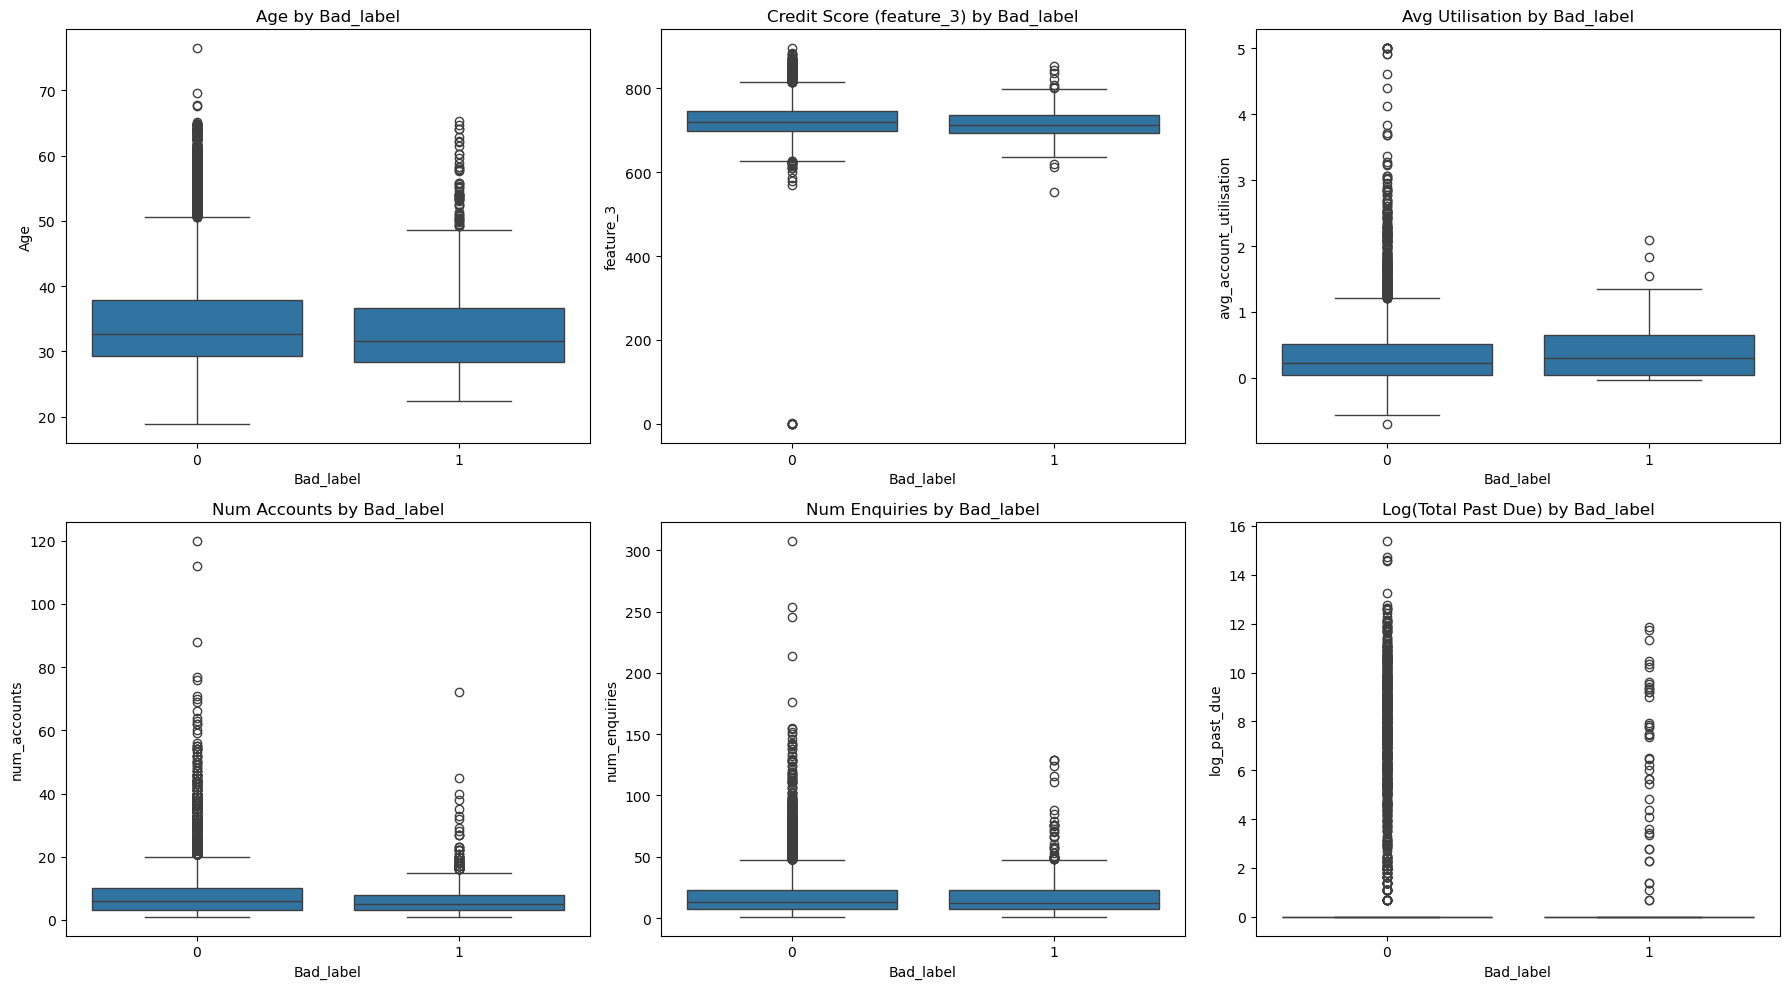

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Age vs Bad_label
sns.boxplot(data=master_df, x='Bad_label', y='Age', ax=axes[0,0])
axes[0,0].set_title('Age by Bad_label')

# Credit score (feature_3) vs Bad_label
master_df['feature_3'] = pd.to_numeric(master_df['feature_3'], errors='coerce')
sns.boxplot(data=master_df, x='Bad_label', y='feature_3', ax=axes[0,1])
axes[0,1].set_title('Credit Score (feature_3) by Bad_label')

# Utilisation vs Bad_label
sns.boxplot(data=master_df, x='Bad_label', y='avg_account_utilisation', ax=axes[0,2])
axes[0,2].set_title('Avg Utilisation by Bad_label')

# num_accounts vs Bad_label
sns.boxplot(data=master_df, x='Bad_label', y='num_accounts', ax=axes[1,0])
axes[1,0].set_title('Num Accounts by Bad_label')

# num_enquiries vs Bad_label
sns.boxplot(data=master_df, x='Bad_label', y='num_enquiries', ax=axes[1,1])
axes[1,1].set_title('Num Enquiries by Bad_label')

# total_amt_past_due vs Bad_label (log scale since likely skewed)
master_df['log_past_due'] = np.log1p(master_df['total_amt_past_due'])
sns.boxplot(data=master_df, x='Bad_label', y='log_past_due', ax=axes[1,2])
axes[1,2].set_title('Log(Total Past Due) by Bad_label')

plt.tight_layout()
plt.show()

## Section 6: Weight of Evidence (WOE) & Information Value (IV)

**What is WOE?** For each feature, we split values into bins (groups), then for each bin calculate:

WOE = ln( % of Good customers in this bin / % of Bad customers in this bin )

A positive WOE means a bin has relatively MORE good customers (safer). A negative WOE means 
relatively MORE bad customers (riskier). This transforms any feature - numeric or categorical - 
into a single consistent risk scale, and naturally handles missing values as their own bin.

**What is IV?** Information Value summarizes WOE across ALL bins of a feature into one number, 
telling us how predictive that entire feature is overall:

- IV < 0.02: Not useful for prediction
- IV 0.02-0.1: Weak predictor
- IV 0.1-0.3: Medium predictor  
- IV 0.3-0.5: Strong predictor
- IV > 0.5: Suspiciously strong (often a data leakage red flag - investigate before trusting)

We'll compute IV for every feature, then keep only the ones that clear a minimum bar (typically IV > 0.02).

In [17]:
def calculate_woe_iv(df, feature, target, bins=10, min_bin_pct=0.01):
    """
    Calculates WOE and IV for a single feature against the target.
    For categorical features, rare categories (below min_bin_pct of total) are grouped into
    'Rare_Combined' first - prevents tiny bins from producing artificially extreme, meaningless WOE.
    """
    data = df[[feature, target]].copy()
    n = len(data)
    
    if pd.api.types.is_numeric_dtype(data[feature]) and data[feature].nunique() > bins:
        data['bin'] = pd.qcut(data[feature], q=bins, duplicates='drop')
        data['bin'] = data['bin'].astype(str)
        data.loc[data[feature].isnull(), 'bin'] = 'Missing'
    else:
        data['bin'] = data[feature].astype(str).replace('nan', 'Missing')
        # Group rare categories (appearing in less than min_bin_pct of data) to avoid tiny,
        # unreliable bins that inflate IV artificially
        value_counts = data['bin'].value_counts(normalize=True)
        rare_categories = value_counts[value_counts < min_bin_pct].index
        data.loc[data['bin'].isin(rare_categories), 'bin'] = 'Rare_Combined'
    
    grouped = data.groupby('bin')[target].agg(['count', 'sum'])
    grouped.columns = ['total', 'bad']
    grouped['good'] = grouped['total'] - grouped['bad']
    
    total_good = grouped['good'].sum()
    total_bad = grouped['bad'].sum()
    
    grouped['pct_good'] = (grouped['good'] + 0.5) / (total_good + 0.5)
    grouped['pct_bad'] = (grouped['bad'] + 0.5) / (total_bad + 0.5)
    
    grouped['woe'] = np.log(grouped['pct_good'] / grouped['pct_bad'])
    grouped['iv_component'] = (grouped['pct_good'] - grouped['pct_bad']) * grouped['woe']
    
    iv = grouped['iv_component'].sum()
    
    return grouped, iv

print("WOE/IV function defined (rare categories are grouped before WOE is calculated).")

WOE/IV function defined (rare categories are grouped before WOE is calculated).


In [18]:
# Candidate features: engineered numeric features + demographic features (excluding IDs/dates already handled)
exclude_cols = ['customer_no', 'Bad_label', 'dt_opened', 'entry_time', 'DOB',
                 'earliest_account_opened', 'most_recent_account_opened',
                 'most_recent_enquiry', 'earliest_enquiry']

candidate_features = [c for c in master_df.columns if c not in exclude_cols]

iv_results = []
for feat in candidate_features:
    try:
        _, iv = calculate_woe_iv(master_df, feat, 'Bad_label')
        iv_results.append({'Feature': feat, 'IV': iv})
    except Exception as e:
        iv_results.append({'Feature': feat, 'IV': np.nan})

iv_df = pd.DataFrame(iv_results).sort_values('IV', ascending=False)

print("=== Information Value by Feature (sorted, top 25) ===")
print(iv_df.head(25).to_string(index=False))

print(f"\nFeatures with IV > 0.02 (usable): {(iv_df['IV'] > 0.02).sum()} out of {len(iv_df)}")
print(f"Features with IV > 0.5 (check for leakage!): {(iv_df['IV'] > 0.5).sum()}")

=== Information Value by Feature (sorted, top 25) ===
                Feature       IV
     total_credit_limit 0.147535
             feature_52 0.113877
             feature_53 0.110782
avg_account_utilisation 0.110220
max_account_utilisation 0.099903
             feature_51 0.094841
             feature_50 0.092685
             feature_16 0.064902
              feature_3 0.063782
             feature_15 0.050277
           num_accounts 0.046299
   avg_rate_of_interest 0.046088
             feature_39 0.044716
                    Age 0.041418
             feature_28 0.039871
             feature_45 0.037959
   has_negative_balance 0.037618
              feature_7 0.035946
             feature_41 0.035128
             feature_43 0.033928
             feature_65 0.033455
             feature_14 0.033419
             feature_44 0.033401
             feature_12 0.031902
    num_closed_accounts 0.030534

Features with IV > 0.02 (usable): 38 out of 84
Features with IV > 0.5 (check for leakag

In [19]:
selected_features = iv_df[iv_df['IV'] > 0.02]['Feature'].tolist()

print(f"Selected {len(selected_features)} features with IV > 0.02:")
for feat in selected_features:
    iv_val = iv_df[iv_df['Feature'] == feat]['IV'].values[0]
    print(f"  {feat}: IV = {iv_val:.4f}")

# Build final modeling dataset
model_df = master_df[selected_features + ['Bad_label']].copy()
print(f"\nFinal modeling dataset shape: {model_df.shape}")

Selected 38 features with IV > 0.02:
  total_credit_limit: IV = 0.1475
  feature_52: IV = 0.1139
  feature_53: IV = 0.1108
  avg_account_utilisation: IV = 0.1102
  max_account_utilisation: IV = 0.0999
  feature_51: IV = 0.0948
  feature_50: IV = 0.0927
  feature_16: IV = 0.0649
  feature_3: IV = 0.0638
  feature_15: IV = 0.0503
  num_accounts: IV = 0.0463
  avg_rate_of_interest: IV = 0.0461
  feature_39: IV = 0.0447
  Age: IV = 0.0414
  feature_28: IV = 0.0399
  feature_45: IV = 0.0380
  has_negative_balance: IV = 0.0376
  feature_7: IV = 0.0359
  feature_41: IV = 0.0351
  feature_43: IV = 0.0339
  feature_65: IV = 0.0335
  feature_14: IV = 0.0334
  feature_44: IV = 0.0334
  feature_12: IV = 0.0319
  num_closed_accounts: IV = 0.0305
  feature_71: IV = 0.0301
  feature_64: IV = 0.0298
  feature_56: IV = 0.0295
  feature_60: IV = 0.0285
  feature_29: IV = 0.0275
  feature_1: IV = 0.0264
  feature_26: IV = 0.0252
  total_high_credit: IV = 0.0237
  feature_66: IV = 0.0234
  feature_63: IV 

## Section 7: WOE Transformation & Preprocessing Pipeline

Industry-standard credit scorecards don't feed raw features into Logistic Regression - they 
transform every feature into its WOE value first. This has two major advantages: it turns 
every feature (numeric or categorical) into the same consistent scale, and it means the 
resulting Logistic Regression coefficients directly reflect risk in a way that's interpretable 
and auditable - important in banking, where regulators often require model explainability.

In [20]:
def get_woe_mapping(df, feature, target, bins=10, min_bin_pct=0.01):
    """Returns the bin edges/categories and their WOE values, so we can apply this
    mapping consistently to both train and test data (fit on train only!)."""
    data = df[[feature, target]].copy()
    is_numeric = pd.api.types.is_numeric_dtype(data[feature]) and data[feature].nunique() > bins
    
    if is_numeric:
        data['bin'], bin_edges = pd.qcut(data[feature], q=bins, duplicates='drop', retbins=True)
        data['bin'] = data['bin'].astype(str)
        data.loc[data[feature].isnull(), 'bin'] = 'Missing'
    else:
        bin_edges = None
        data['bin'] = data[feature].astype(str).replace('nan', 'Missing')
        value_counts = data['bin'].value_counts(normalize=True)
        rare_categories = value_counts[value_counts < min_bin_pct].index.tolist()
        data.loc[data['bin'].isin(rare_categories), 'bin'] = 'Rare_Combined'
    
    grouped = data.groupby('bin')[target].agg(['count', 'sum'])
    grouped.columns = ['total', 'bad']
    grouped['good'] = grouped['total'] - grouped['bad']
    total_good, total_bad = grouped['good'].sum(), grouped['bad'].sum()
    grouped['pct_good'] = (grouped['good'] + 0.5) / (total_good + 0.5)
    grouped['pct_bad'] = (grouped['bad'] + 0.5) / (total_bad + 0.5)
    grouped['woe'] = np.log(grouped['pct_good'] / grouped['pct_bad'])
    
    woe_map = grouped['woe'].to_dict()
    return woe_map, bin_edges, is_numeric, rare_categories if not is_numeric else None

print("WOE mapping function defined.")

WOE mapping function defined.


In [21]:
from sklearn.model_selection import train_test_split

X = model_df.drop(columns=['Bad_label'])
y = model_df['Bad_label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Train shape: {X_train.shape}, Bad rate: {y_train.mean()*100:.2f}%")
print(f"Test shape: {X_test.shape}, Bad rate: {y_test.mean()*100:.2f}%")

Train shape: (19116, 38), Bad rate: 4.20%
Test shape: (4780, 38), Bad rate: 4.21%


In [22]:
train_with_target = X_train.copy()
train_with_target['Bad_label'] = y_train

woe_mappings = {}
X_train_woe = pd.DataFrame(index=X_train.index)
X_test_woe = pd.DataFrame(index=X_test.index)

for feat in selected_features:
    woe_map, bin_edges, is_numeric, rare_cats = get_woe_mapping(train_with_target, feat, 'Bad_label')
    woe_mappings[feat] = {'map': woe_map, 'bin_edges': bin_edges, 'is_numeric': is_numeric, 'rare_cats': rare_cats}
    
    if is_numeric:
        train_binned = pd.cut(X_train[feat], bins=bin_edges, include_lowest=True).astype(str)
        train_binned[X_train[feat].isnull()] = 'Missing'
        test_binned = pd.cut(X_test[feat], bins=bin_edges, include_lowest=True).astype(str)
        test_binned[X_test[feat].isnull()] = 'Missing'
    else:
        train_binned = X_train[feat].astype(str).replace('nan', 'Missing')
        train_binned[train_binned.isin(rare_cats)] = 'Rare_Combined'
        test_binned = X_test[feat].astype(str).replace('nan', 'Missing')
        test_binned[test_binned.isin(rare_cats)] = 'Rare_Combined'
    
    # Map to WOE; any category seen in test but not train (unseen) gets WOE = 0 (neutral)
    X_train_woe[feat] = train_binned.map(woe_map).fillna(0)
    X_test_woe[feat] = test_binned.map(woe_map).fillna(0)

print("WOE transformation applied to train and test.")
print(f"X_train_woe shape: {X_train_woe.shape}")
print(f"X_test_woe shape: {X_test_woe.shape}")
X_train_woe.head()

WOE transformation applied to train and test.
X_train_woe shape: (19116, 38)
X_test_woe shape: (4780, 38)


,total_credit_limit,feature_52,feature_53,avg_account_utilisation,max_account_utilisation,feature_51,feature_50,feature_16,feature_3,feature_15,...,feature_60,feature_29,feature_1,feature_26,total_high_credit,feature_66,feature_63,feature_13,avg_enquiry_amt,feature_30
20263,0.023746,-0.259871,-0.255496,-0.374659,-0.207486,-0.258044,-0.259392,0.248513,0.345422,0.089243,...,-0.011807,-0.088484,0.072295,-0.097314,0.228507,0.021815,-0.034885,0.063681,-0.069716,0.003794
13065,0.003662,0.410378,0.150119,0.231815,0.421844,0.179823,0.302445,-0.272210,-0.146665,0.089243,...,-0.011807,0.041792,-0.170011,-0.097314,-0.158061,0.021815,-0.073195,-0.098381,0.046450,-0.095703
6088,0.333596,0.243255,0.049969,-0.374659,-0.207486,0.298084,0.302445,-0.014801,0.384028,-0.273937,...,-0.011807,0.041792,-0.170011,0.271368,0.228507,0.021815,0.264584,-0.098381,-0.174211,0.207110
5499,0.023746,0.273025,0.532472,0.005803,0.157106,0.298108,0.302445,-0.118384,-0.253971,0.089243,...,-0.011807,-0.021228,0.204804,-0.097314,0.079490,0.021815,-0.296507,-0.098381,0.236784,-0.184933
21048,-0.132051,0.410378,0.532472,0.122263,0.213296,0.298108,0.302445,0.472745,-0.157005,0.089243,...,-0.011807,0.041792,0.072295,-0.097314,-0.076952,0.021815,0.130420,0.063681,0.133043,-0.019410


## Section 8: Model Training — Logistic Regression Scorecard

Logistic Regression on WOE-transformed features is the traditional, industry-standard approach 
for credit scorecards - primarily because it's fully interpretable and auditable (each 
coefficient has a clear, explainable meaning), which regulators typically require. We'll also 
train a Random Forest and XGBoost for comparison, since the project brief doesn't restrict us 
to one model type - but Logistic Regression on WOE is our primary candidate for production.

In [23]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_woe, y_train)

train_probs = log_reg.predict_proba(X_train_woe)[:, 1]
test_probs = log_reg.predict_proba(X_test_woe)[:, 1]

print("Logistic Regression trained.")
print(f"Train predicted probability range: {train_probs.min():.4f} to {train_probs.max():.4f}")
print(f"Test predicted probability range: {test_probs.min():.4f} to {test_probs.max():.4f}")

Logistic Regression trained.
Train predicted probability range: 0.0001 to 0.3171
Test predicted probability range: 0.0001 to 0.3127


In [24]:
from sklearn.metrics import roc_auc_score

def gini_score(y_true, y_pred_proba):
    """Gini = 2 * AUC - 1. This is the standard relationship between the two metrics."""
    auc = roc_auc_score(y_true, y_pred_proba)
    return 2 * auc - 1

train_gini = gini_score(y_train, train_probs) * 100
test_gini = gini_score(y_test, test_probs) * 100

print(f"Train Gini: {train_gini:.2f}")
print(f"Test Gini: {test_gini:.2f}")
print(f"\nBenchmark to beat: 37.9")
print(f"Result: {'BEAT the benchmark! 🎉' if test_gini > 37.9 else 'Below benchmark - needs improvement'}")

Train Gini: 41.90
Test Gini: 32.45

Benchmark to beat: 37.9
Result: Below benchmark - needs improvement


=== Decile Rank-Ordering (Test Set) ===
        count  bad_count  bad_rate
decile                            
10        478         39  0.081590
9         478         35  0.073222
8         478         27  0.056485
7         478         22  0.046025
6         478         21  0.043933
5         478         25  0.052301
4         478         14  0.029289
3         478          7  0.014644
2         478          6  0.012552
1         478          5  0.010460


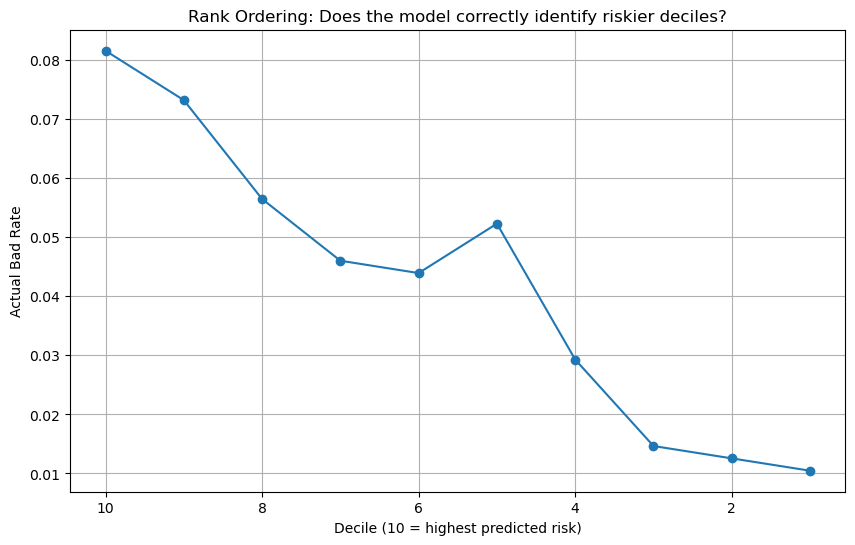

In [25]:
decile_df = pd.DataFrame({'y_true': y_test.values, 'predicted_prob': test_probs})
decile_df['decile'] = pd.qcut(decile_df['predicted_prob'], q=10, labels=False, duplicates='drop') + 1

rank_order = decile_df.groupby('decile').agg(
    count=('y_true', 'count'),
    bad_count=('y_true', 'sum')
)
rank_order['bad_rate'] = rank_order['bad_count'] / rank_order['count']
rank_order = rank_order.sort_index(ascending=False)  # decile 10 = highest risk first

print("=== Decile Rank-Ordering (Test Set) ===")
print(rank_order)

plt.figure(figsize=(10, 6))
plt.plot(range(10, 0, -1), rank_order['bad_rate'].values, marker='o')
plt.xlabel('Decile (10 = highest predicted risk)')
plt.ylabel('Actual Bad Rate')
plt.title('Rank Ordering: Does the model correctly identify riskier deciles?')
plt.gca().invert_xaxis()
plt.grid(True)
plt.show()

### Variant evaluation

Besides the 38-feature model above (**Variant A**), two pruned variants are tested: correlated features (WOE correlation > 0.7) are removed, keeping the feature with the higher IV in each pair, which leaves **23 features**. **Variant B** uses 10-bin WOE and **Variant C** uses 5-bin WOE. Cross-validation below is run on the training split only.

In [26]:
# Step 1: Correlation check
corr_matrix = X_train_woe.corr().abs()
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if corr_matrix.iloc[i, j] > 0.7:
            high_corr_pairs.append({
                'Feature_1': corr_matrix.columns[i],
                'Feature_2': corr_matrix.columns[j],
                'Correlation': corr_matrix.iloc[i, j]
            })
high_corr_df = pd.DataFrame(high_corr_pairs).sort_values('Correlation', ascending=False)
print(f"Found {len(high_corr_df)} highly correlated feature pairs (>0.7)")

# Step 2: Drop weaker feature from each correlated pair
features_to_drop = set()
for _, row in high_corr_df.iterrows():
    feat1, feat2 = row['Feature_1'], row['Feature_2']
    if feat1 in features_to_drop or feat2 in features_to_drop:
        continue
    iv1 = iv_df[iv_df['Feature'] == feat1]['IV'].values[0]
    iv2 = iv_df[iv_df['Feature'] == feat2]['IV'].values[0]
    weaker = feat2 if iv1 >= iv2 else feat1
    features_to_drop.add(weaker)

final_features = [f for f in selected_features if f not in features_to_drop]
print(f"Dropping {len(features_to_drop)} redundant features. Final count: {len(final_features)}")

X_train_woe_final = X_train_woe[final_features]
X_test_woe_final = X_test_woe[final_features]

Found 27 highly correlated feature pairs (>0.7)
Dropping 15 redundant features. Final count: 23


In [27]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Using roc_auc scoring since Gini = 2*AUC - 1 (same ranking, just rescaled)
cv_auc_scores = cross_val_score(LogisticRegression(max_iter=1000, random_state=42),
                                  X_train_woe_final, y_train, cv=cv, scoring='roc_auc')
cv_gini_scores = (cv_auc_scores * 2 - 1) * 100

print("Cross-validated Gini scores across 5 folds (Variant B: 10-bin WOE, 23 pruned features):")
print(cv_gini_scores)
print(f"\nMean Gini: {cv_gini_scores.mean():.2f}")
print(f"Std Gini: {cv_gini_scores.std():.2f}")
print(f"Range: {cv_gini_scores.min():.2f} to {cv_gini_scores.max():.2f}")

Cross-validated Gini scores across 5 folds (Variant B: 10-bin WOE, 23 pruned features):
[43.57406531 37.78494403 38.09241059 45.95628767 30.97380856]

Mean Gini: 39.28
Std Gini: 5.21
Range: 30.97 to 45.96


In [28]:
# Variant C: rebuild WOE features with 5 bins instead of 10
X_train_woe_v3 = pd.DataFrame(index=X_train.index)
X_test_woe_v3 = pd.DataFrame(index=X_test.index)

for feat in final_features:
    woe_map, bin_edges, is_numeric, rare_cats = get_woe_mapping(train_with_target, feat, 'Bad_label', bins=5)
    
    if is_numeric:
        train_binned = pd.cut(X_train[feat], bins=bin_edges, include_lowest=True).astype(str)
        train_binned[X_train[feat].isnull()] = 'Missing'
        test_binned = pd.cut(X_test[feat], bins=bin_edges, include_lowest=True).astype(str)
        test_binned[X_test[feat].isnull()] = 'Missing'
    else:
        train_binned = X_train[feat].astype(str).replace('nan', 'Missing')
        train_binned[train_binned.isin(rare_cats)] = 'Rare_Combined'
        test_binned = X_test[feat].astype(str).replace('nan', 'Missing')
        test_binned[test_binned.isin(rare_cats)] = 'Rare_Combined'
    
    X_train_woe_v3[feat] = train_binned.map(woe_map).fillna(0)
    X_test_woe_v3[feat] = test_binned.map(woe_map).fillna(0)

log_reg_v3 = LogisticRegression(max_iter=1000, random_state=42)
log_reg_v3.fit(X_train_woe_v3, y_train)

train_gini_v3 = gini_score(y_train, log_reg_v3.predict_proba(X_train_woe_v3)[:, 1]) * 100
test_gini_v3 = gini_score(y_test, log_reg_v3.predict_proba(X_test_woe_v3)[:, 1]) * 100

print(f"Train Gini (5 bins): {train_gini_v3:.2f}")
print(f"Test Gini (5 bins): {test_gini_v3:.2f}")
print(f"Gap: {train_gini_v3 - test_gini_v3:.2f}")

Train Gini (5 bins): 39.41
Test Gini (5 bins): 32.66
Gap: 6.75


In [29]:
# Cross-validated Gini for Variant C (5-bin WOE), same folds as Variant B for a fair comparison
cv_auc_scores_v3 = cross_val_score(LogisticRegression(max_iter=1000, random_state=42),
                                   X_train_woe_v3, y_train, cv=cv, scoring='roc_auc')
cv_gini_scores_v3 = (cv_auc_scores_v3 * 2 - 1) * 100

print("Cross-validated Gini (5-bin WOE, 23 features):")
print(cv_gini_scores_v3)
print(f"\nMean Gini: {cv_gini_scores_v3.mean():.2f} (std: {cv_gini_scores_v3.std():.2f})")

print(f"\n=== CV COMPARISON (training split, 5-fold) ===")
print(f"10-bin, 23 features - CV Mean Gini: {cv_gini_scores.mean():.2f} (std {cv_gini_scores.std():.2f})")
print(f"5-bin, 23 features  - CV Mean Gini: {cv_gini_scores_v3.mean():.2f} (std {cv_gini_scores_v3.std():.2f})")
print(f"Benchmark: 37.9")

Cross-validated Gini (5-bin WOE, 23 features):
[41.90791582 37.1969697  36.41380016 43.34324996 29.09451103]

Mean Gini: 37.59 (std: 5.01)

=== CV COMPARISON (training split, 5-fold) ===
10-bin, 23 features - CV Mean Gini: 39.28 (std 5.21)
5-bin, 23 features  - CV Mean Gini: 37.59 (std 5.01)
Benchmark: 37.9


In [30]:
# Saved model (Variant A): all 38 IV-selected features, 10-bin WOE (X_train_woe / X_test_woe from the WOE step)
final_model = LogisticRegression(max_iter=1000, random_state=42)
final_model.fit(X_train_woe, y_train)

final_test_probs = final_model.predict_proba(X_test_woe)[:, 1]
final_test_gini = gini_score(y_test, final_test_probs) * 100

print("SAVED MODEL (Variant A): Logistic Regression, WOE-transformed, 38 features, 10 bins")
print(f"Held-out test set Gini: {final_test_gini:.2f}")
print("(Cross-validation for this exact 38-feature model was not run; CV figures above are for the 23-feature variants.)")
print("Benchmark: 37.9")

SAVED MODEL (Variant A): Logistic Regression, WOE-transformed, 38 features, 10 bins
Held-out test set Gini: 32.45
(Cross-validation for this exact 38-feature model was not run; CV figures above are for the 23-feature variants.)
Benchmark: 37.9


In [31]:
coef_df = pd.DataFrame({
    'Feature': selected_features,
    'Coefficient': final_model.coef_[0]
}).sort_values('Coefficient', key=abs, ascending=False)

print("Top 15 features by |coefficient| (WOE scale; coefficients are negative because higher WOE = safer = lower predicted bad probability):")
print(coef_df.head(15).to_string(index=False))

Top 15 features by |coefficient| (WOE scale; coefficients are negative because higher WOE = safer = lower predicted bad probability):
                Feature  Coefficient
        avg_enquiry_amt    -1.260307
             feature_45    -1.040109
              feature_3    -0.851670
              feature_7    -0.761265
             feature_39    -0.656342
             feature_44    -0.628474
             feature_53    -0.618197
   avg_rate_of_interest    -0.604661
             feature_29    -0.587754
             feature_16    -0.561543
             feature_63    -0.549163
      total_high_credit    -0.540027
             feature_60    -0.511710
             feature_14    -0.411533
max_account_utilisation    -0.397455


In [32]:
import joblib

joblib.dump(final_model, 'credit_risk_scorecard_model.pkl')
joblib.dump(woe_mappings, 'woe_mappings.pkl')

print("Model and WOE mappings saved.")

Model and WOE mappings saved.


## Section 9: Model Evaluation and Comparison

### Approach
Logistic Regression on WOE-transformed features is the primary model, following standard credit-scorecard practice: coefficients are directly interpretable and auditable, WOE handles missing values and non-linear effects without extra preprocessing, and the result can be converted into a points-based scorecard. Only Logistic Regression was evaluated here; no tree-based or gradient-boosting comparison was run.

### Results

| Variant | Features | WOE bins | 5-fold CV Gini (training split) | Held-out test Gini |
|---|---|---|---|---|
| **A** (saved model) | 38 | 10 | not computed | 32.45 (train 41.90) |
| **B** | 23 (after correlation pruning) | 10 | 39.28 (std 5.21, folds 30.97 to 45.96) | not computed |
| **C** | 23 | 5 | 37.59 (std 5.01) | 32.66 (train 39.41) |
| Bank benchmark | n/a | n/a | 37.9 | 37.9 |

### Reading the evidence
* **Cross-validation (Variant B) sits above the benchmark** (39.28 vs 37.9), but the margin is 1.4 points while the fold-to-fold spread is 31 to 46, so this is not a reliable win.
* **Held-out test results (Variants A and C) sit below the benchmark** (32.45 and 32.66). The test set has only 201 bad customers, so these numbers are noisy too.
* **10 bins beat 5 bins** on the same 23 features in cross-validation (39.28 vs 37.59). The effect of pruning from 38 to 23 features cannot be isolated, because the 38-feature model was never cross-validated.
* **Rank-ordering is useful even if the Gini is not conclusive.** On the test set, Variant A's top decile has a bad rate of 8.2% against 1.0% in the bottom decile (about 8x), and the top three deciles contain 101 of the 201 bad customers (50%). Ordering is broadly monotonic with a bump at decile 5.

**Verdict:** the evidence does not show a reliable improvement over the benchmark. The model is roughly comparable to it, with large uncertainty from the small number of bad customers.

## Section 10: Feature Insights and Business Application

### Strongest signals
All Information Values are modest (the highest is 0.148 for `total_credit_limit`), so no single feature is a strong predictor; the model combines many weak signals. The largest coefficients in the saved model belong to `avg_enquiry_amt`, `feature_45`, `feature_3`, `feature_7` and `feature_39`. Meanings of the anonymised `feature_*` columns are **inferred, not confirmed**: `feature_45` looks like an email domain and `feature_3` looks like a credit-score-style number (263 distinct values). Account-level behaviour (`avg_rate_of_interest`, `total_high_credit`, utilisation) also contributes.

### Credit-score-style feature on its own
`feature_3` has a low standalone IV (0.064), so on this sample it is a weak predictor in isolation. The model's signal comes from combining enquiry behaviour, account utilisation and demographic variables.

### Business application
* Use the decile ranking to prioritise collections or early-intervention outreach: the top 30% of customers by predicted risk held about half of the bad customers in the test set.
* Re-validate on a larger, more recent cohort before deployment, given the variance described above.

## Section 11: Challenges Faced

### 1. Multi-table aggregation without leaking or duplicating the target
`Cust_Account` (186,329 rows) and `Cust_Enquiry` (413,188 rows) have many rows per customer, while `Bad_label` exists once per customer. Both tables were aggregated to one row per `customer_no` first, then joined to demographics. A row-count check confirmed 23,896 rows in and 23,896 out.

### 2. Extreme credit-utilisation values
Utilisation ratios were wildly skewed (per-account maximum 5,602x, customer-level averages up to about 2,801x) because many accounts report no or tiny credit limits. Utilisation is therefore calculated per account only where a valid limit exists (48,852 of 186,329 accounts), aggregated per customer and capped at 5x.

### 3. Working with 79 anonymised features
Demographic columns were named `feature_1` to `feature_79` with no documentation. Every feature was scanned for cardinality and value patterns before any modelling decision, e.g. spotting `feature_21` as a date of birth (converted to Age) and `feature_20`, `22`, `47`, `77` as near-unique identifiers (dropped).

### 4. An Information Value bug from high-cardinality categoricals
An early IV calculation gave impossible values (up to 5.99, with 10 features above the 0.5 leakage-warning level) because high-cardinality categoricals such as a job-title field (5,664 distinct values) were binned by exact string, creating thousands of tiny bins. Grouping categories below 1% frequency into one bin fixed it: the maximum IV became 0.15, none exceed 0.5, and 38 of 84 candidate features clear the 0.02 threshold.

### 5. Very few positive cases
Only 1,004 of 23,896 customers (4.2%) are bad. That means about 160 bad customers per validation fold and 201 in the held-out test set, so a single split is noisy. Five-fold stratified cross-validation was used to show the spread (Variant B: 30.97 to 45.96), which is why the headline conclusion is cautious.

### 6. Multicollinearity
27 feature pairs exceeded 0.7 correlation after WOE transformation. Dropping the lower-IV feature in each pair left 23 features. With 10-bin WOE this variant cross-validated at 39.28, so pruning did not obviously hurt, but the 38-feature model was not cross-validated, so the effect of pruning is not isolated.

## Section 12: Conclusion

A credit-risk scorecard was built for current credit-card customers from three joined MySQL tables, predicting 30+ days past due. Three Logistic Regression variants on WOE-transformed features were compared with held-out testing and 5-fold cross-validation. Cross-validation of the pruned 10-bin model (39.28 Gini) is above the bank's 37.9 benchmark, while held-out tests for the other variants (about 32.5) are below it, and fold-to-fold variation is large, so **no reliable improvement over the benchmark is claimed**. The model does rank customers by risk (top decile 8.2% bad vs 1.0% bottom decile).

## Section 13: Limitations and Next Steps

* **Selection leakage:** IV feature selection used all customers before the train/test split, and WOE mappings were fitted on the full training split before cross-validation. Both make validation scores slightly optimistic. A stricter design repeats selection and WOE fitting inside each training fold.
* **Evaluation gaps:** no cross-validation for the 38-feature model and no held-out score for the 23-feature 10-bin model.
* **Single random split:** no out-of-time validation, calibration check or population-stability analysis.
* **Model coverage:** only Logistic Regression was tried; a gradient-boosting comparison would show how much accuracy is traded for interpretability.
* **Anonymised features:** feature meanings are inferred from value patterns.